# 02 · Exploració per a P1: què fa que una avaria no es pugui reparar

Resposta: `final_vida` (1 si la reparació acaba a *End of life*). Cap d'aquestes taules controla les altres variables: les diferències poden venir de qui registra les dades, i per això després caldrà el model multivariant.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd

import comu

pd.set_option("display.max_rows", 40)

mobils = pd.read_csv(comu.PROCESSADES / "mobils.csv")
mobifix = comu.carrega_mobifix()
print(f"Proporció de final de vida: {mobils['final_vida'].mean():.1%} de {len(mobils):,}")

Proporció de final de vida: 15.1% de 5,652


In [2]:
def taxa(df, columna, minim=30):
    """Proporció de final de vida per categoria, amb el nombre de casos."""
    t = df.groupby(columna)["final_vida"].agg(n="size", final_vida="sum", taxa="mean")
    return t[t["n"] >= minim].sort_values("taxa", ascending=False)

def barres(t, titol):
    ax = t["taxa"].sort_values().plot.barh(figsize=(6, 0.3 * len(t) + 1), color="#2a78d6")
    ax.set_xlabel("Proporció de final de vida")
    ax.set_title(titol)
    plt.show()

## Per proveïdor

Si les taxes són molt diferents, el proveïdor és una variable de control imprescindible.

,n,final_vida,taxa
data_provider,,,
Repair Café Toronto,46,19,0.413043
Repair Café Denmark,343,83,0.241983
Repair Café International,689,161,0.233672
Repair Cafe Wales,155,34,0.219355
anstiftung,943,171,0.181336
Repair Connects,35,4,0.114286
The Restart Project,3422,379,0.110754


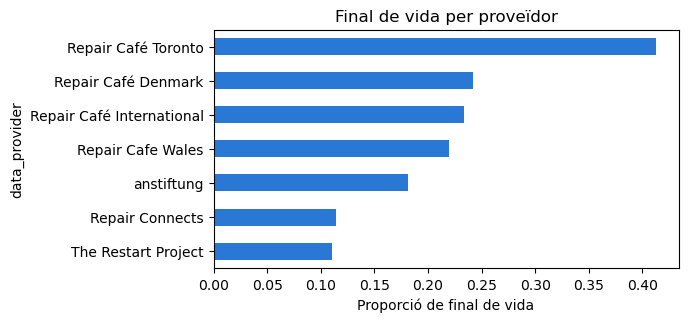

In [3]:
t = taxa(mobils, "data_provider")
display(t)
barres(t, "Final de vida per proveïdor")

## Per país, marca i any de l'esdeveniment

,n,final_vida,taxa
country,,,
ESP,92,26,0.282609
DNK,343,83,0.241983
FRA,256,55,0.214844
NLD,268,54,0.201493
ITA,170,32,0.188235
DEU,999,185,0.185185
CAN,342,62,0.181287
SWE,76,13,0.171053
GBR,1333,226,0.169542


,n,final_vida,taxa
marca,,,
Motorola,126,25,0.198413
Altres,615,121,0.196748
Nokia,133,24,0.180451
Samsung,1020,184,0.180392
Sony,94,16,0.170213
Desconeguda,1918,296,0.154327
Xiaomi,112,17,0.151786
Fairphone,73,10,0.136986
Huawei,190,24,0.126316


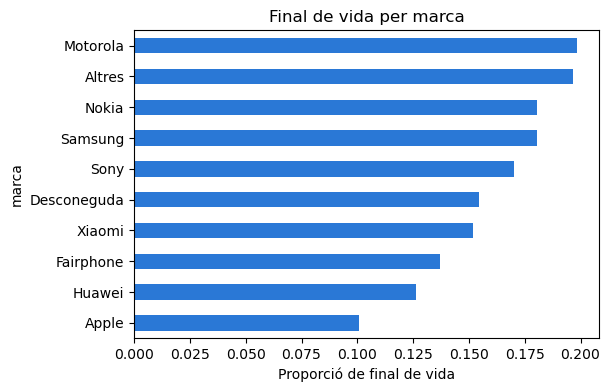

In [4]:
display(taxa(mobils, "country"))
t = taxa(mobils, "marca")
display(t)
barres(t, "Final de vida per marca")

,n,final_vida,taxa
any_event,,,
2012,1,0,0.000000
2013,31,9,0.290323
2014,90,22,0.244444
2015,103,18,0.174757
2016,224,33,0.147321
2017,349,51,0.146132
2018,509,79,0.155206
2019,590,73,0.123729
2020,160,35,0.218750


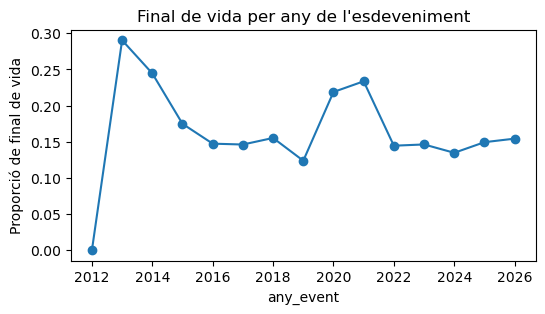

In [5]:
t = taxa(mobils, "any_event", minim=1).sort_index()
display(t)
ax = t["taxa"].plot(marker="o", figsize=(6, 3))
ax.set_ylabel("Proporció de final de vida")
ax.set_title("Final de vida per any de l'esdeveniment")
plt.show()

## Per edat (només la submostra amb edat)

,n,taxa
franja_edat,,
0-1,194,0.092784
2-3,582,0.089347
4-5,522,0.139847
6-8,252,0.190476
9-15,144,0.236111


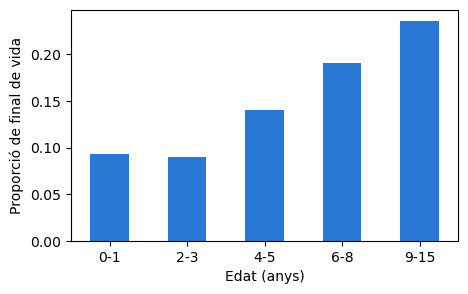

In [6]:
amb_edat = mobils.dropna(subset=["edat_neta"]).copy()
amb_edat["franja_edat"] = pd.cut(amb_edat["edat_neta"], [-1, 1, 3, 5, 8, 15],
                                 labels=["0-1", "2-3", "4-5", "6-8", "9-15"])
t = amb_edat.groupby("franja_edat", observed=True)["final_vida"].agg(n="size", taxa="mean")
display(t)
ax = t["taxa"].plot.bar(figsize=(5, 3), color="#2a78d6", rot=0)
ax.set_xlabel("Edat (anys)")
ax.set_ylabel("Proporció de final de vida")
plt.show()

## Qui registra l'edat

Si l'edat falta sobretot en uns proveïdors, la submostra amb edat no és aleatòria (apartat 8 del disseny).

In [7]:
mobils.assign(te_edat=mobils["edat"].notna()).groupby("data_provider")["te_edat"].agg(n="size", proporcio="mean")

,n,proporcio
data_provider,,
Fixit Clinic,18,0.722222
Repair Cafe Wales,155,0.000000
Repair Café Denmark,343,0.000000
Repair Café International,689,0.426705
Repair Café Toronto,46,0.000000
Repair Connects,35,0.428571
The Restart Project,3422,0.309760
anstiftung,943,0.371156
iFixit,1,1.000000


## Per tipus d'avaria (MobiFix)

El conjunt agregat no té el tipus d'avaria: de moment només el tenim a MobiFix (fins al 2020).

,n,final_vida,taxa
grup_avaria,,,
Danys interns i aigua,35,8,0.228571
Desconegut,360,79,0.219444
Altres,195,38,0.194872
Bateria i alimentació,230,25,0.108696
Botons i connectors,117,12,0.102564
Programari i configuració,200,15,0.075000
Pantalla,619,28,0.045234
Port de càrrega,86,3,0.034884


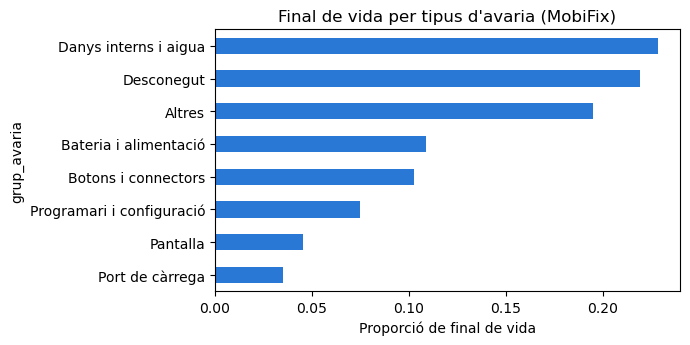

In [8]:
mf = mobifix[mobifix["repair_status"] != "Unknown"].copy()
mf["final_vida"] = (mf["repair_status"] == "End of life").astype(int)
t = taxa(mf, "grup_avaria", minim=1)
display(t)
barres(t, "Final de vida per tipus d'avaria (MobiFix)")

## Motius de final de vida

In [9]:
eol = mobils[mobils["final_vida"] == 1]
print(f"Amb motiu: {eol['repair_barrier_if_end_of_life'].notna().sum()} de {len(eol)}")
eol["repair_barrier_if_end_of_life"].value_counts()

Amb motiu: 308 de 855


repair_barrier_if_end_of_life
Spare parts not available           82
Repair information not available    61
Spare parts too expensive           56
Lack of equipment                   49
No way to open product              31
Product too worn out                29
Name: count, dtype: int64